1. DATA LOADING AND INITIAL INSPECTION
Successfully loaded with latin-1 encoding
Dataset shape: (953, 24)
Columns: ['track_name', 'artist(s)_name', 'artist_count', 'released_year', 'released_month', 'released_day', 'in_spotify_playlists', 'in_spotify_charts', 'streams', 'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists', 'in_deezer_charts', 'in_shazam_charts', 'bpm', 'key', 'mode', 'danceability_%', 'valence_%', 'energy_%', 'acousticness_%', 'instrumentalness_%', 'liveness_%', 'speechiness_%']

2. DATA CLEANING FOR EDA
Missing values before drop: 146

3. VARIABLE IDENTIFICATION
>>> DEPENDENT VARIABLE (Target):
    - 'streams': Continuous variable representing track popularity.
    - Note: Highly skewed, will use 'log_streams' for analysis.

>>> INDEPENDENT VARIABLES (Features):
    - Audio Metrics: danceability_%, valence_%, energy_%, acousticness_%, etc.
    - Temporal: released_year, released_month, released_day
    - Platform: in_spotify_playlists, in_apple_charts, etc.


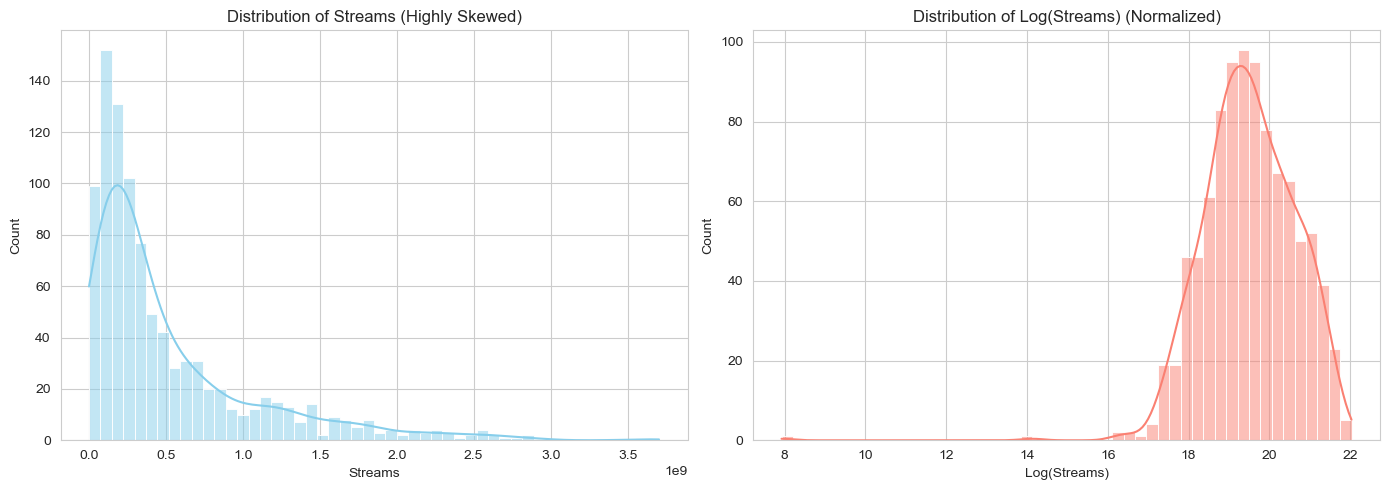


5. CORRELATION ANALYSIS


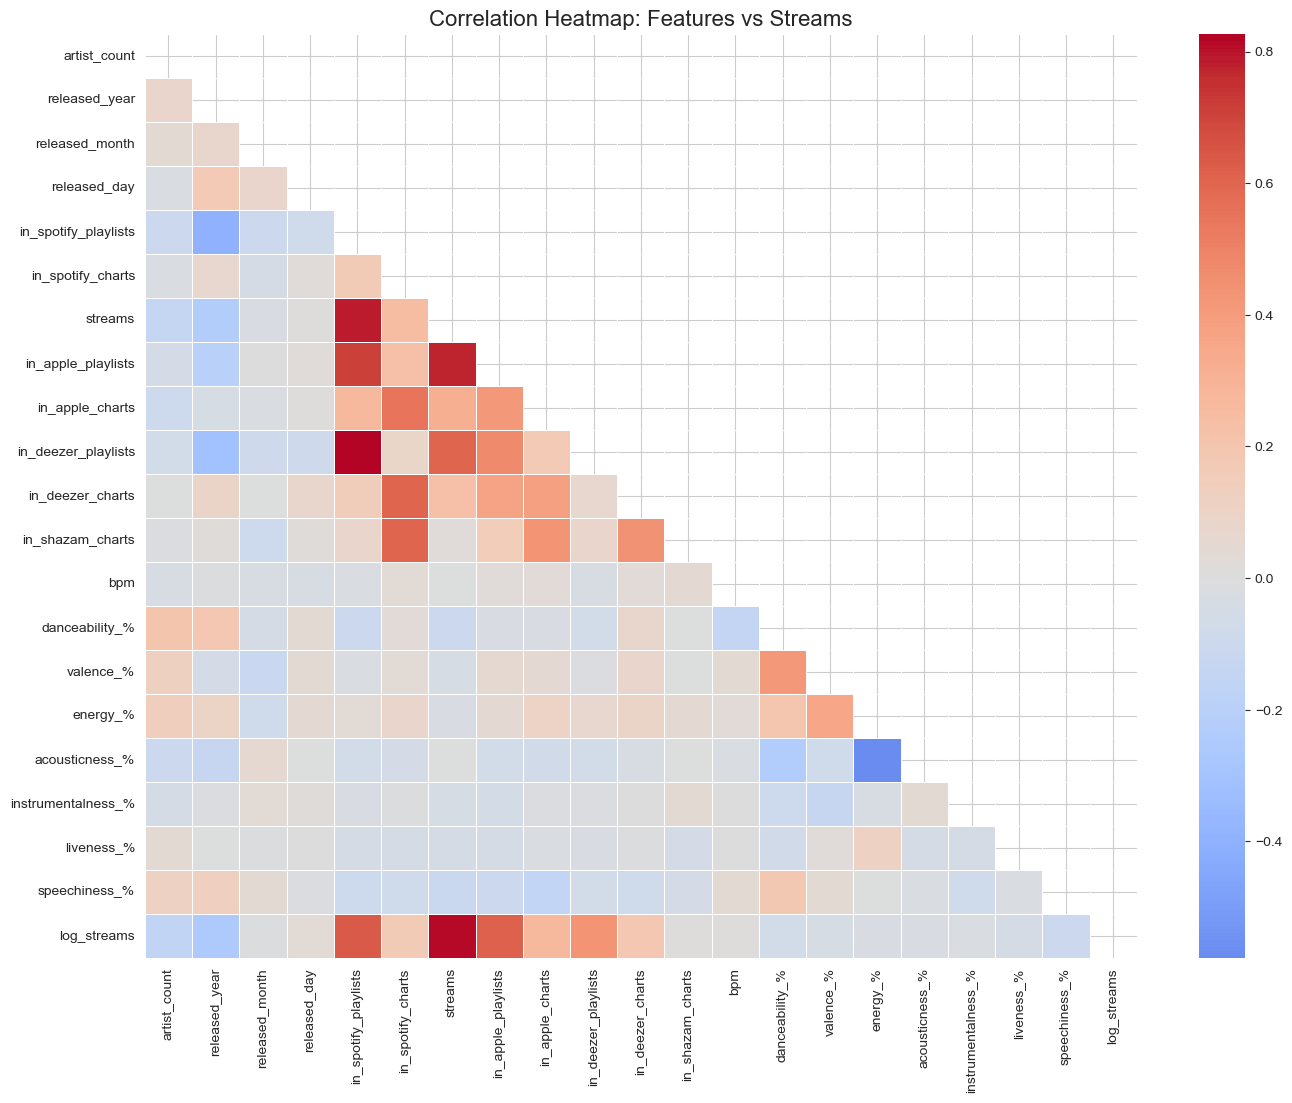

Top 10 Variables Correlated with Streams:
streams                 1.000000
log_streams             0.814736
in_spotify_playlists    0.789822
in_apple_playlists      0.772063
in_deezer_playlists     0.598131
in_apple_charts         0.320234
in_spotify_charts       0.245821
in_deezer_charts        0.228598
in_shazam_charts        0.024981
released_day            0.010598
Name: streams, dtype: float64

6. FEATURE RELATIONSHIPS


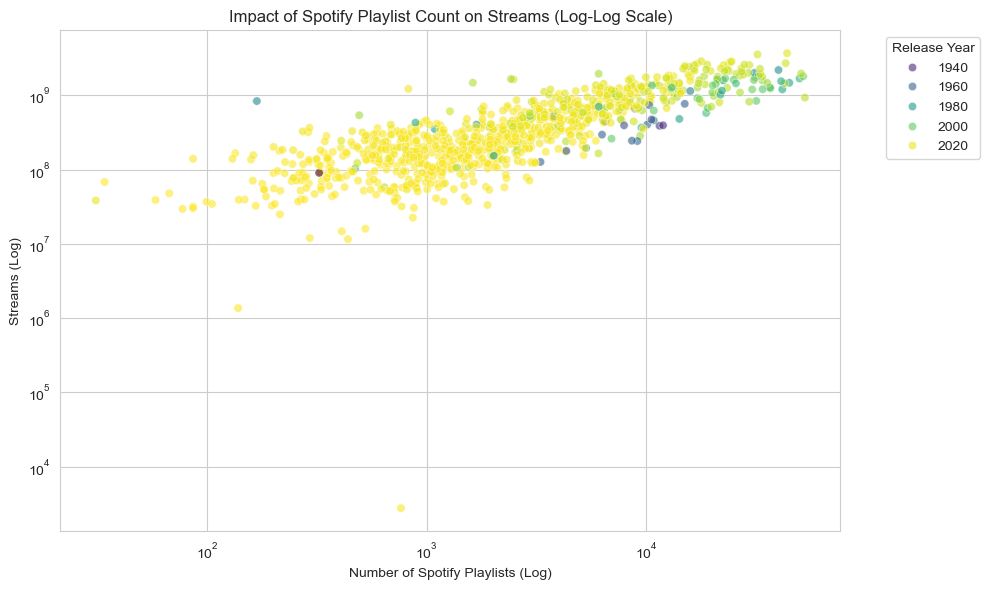

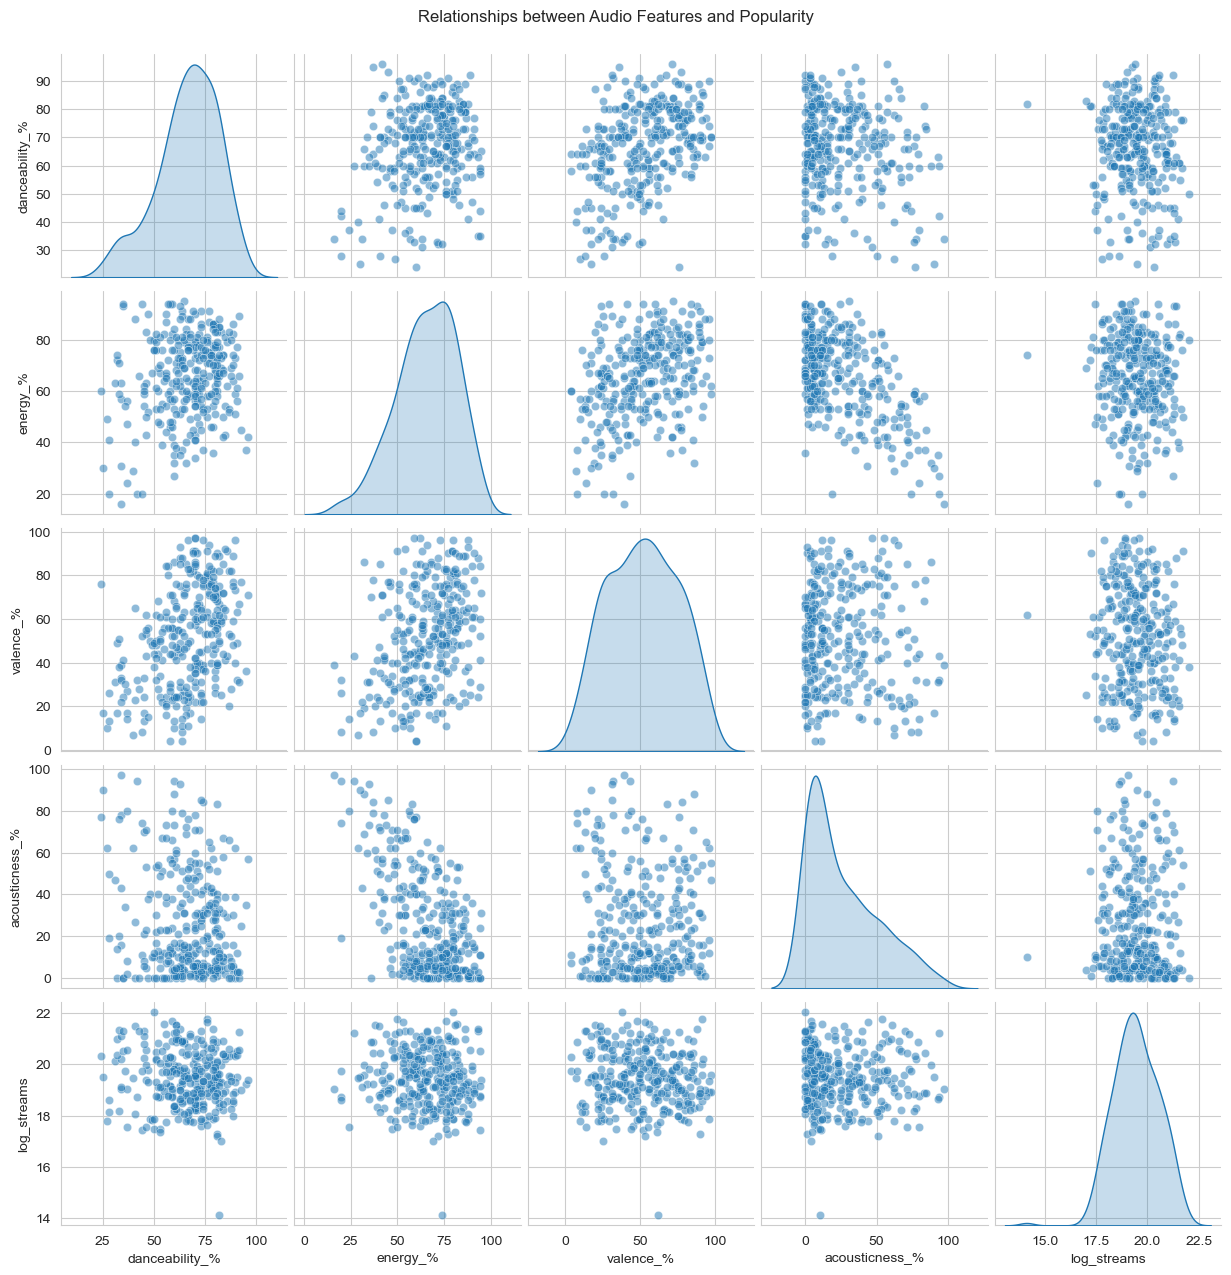

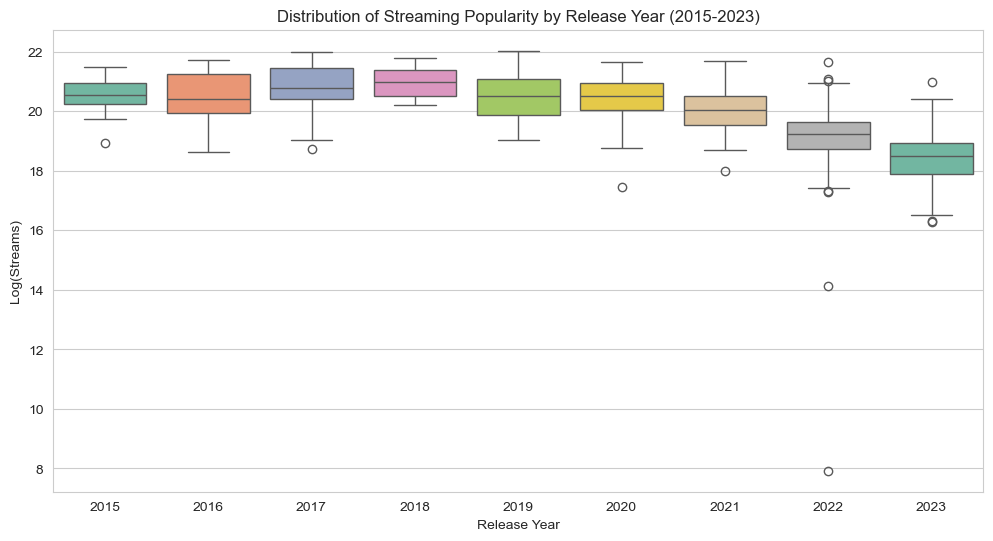

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# SETUP & STYLE
# =============================================================================
# Set plotting style for professional visualization suitable for reports
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (10, 6)

# =============================================================================
# 1. DATA LOADING AND INITIAL INSPECTION
# =============================================================================
print("="*60)
print("1. DATA LOADING AND INITIAL INSPECTION")
print("="*60)

# Robust loading mechanism for different encodings
try:
    df = pd.read_csv('spotify_2023.csv', encoding='utf-8')
    print("Successfully loaded with utf-8 encoding")
except UnicodeDecodeError:
    try:
        df = pd.read_csv('spotify_2023.csv', encoding='latin-1')
        print("Successfully loaded with latin-1 encoding")
    except Exception as e:
        print(f"Error loading file: {e}")
        df = None

if df is not None:
    df_eda = df.copy()
    print(f"Dataset shape: {df_eda.shape}")
    print(f"Columns: {df_eda.columns.tolist()}")

# =============================================================================
# 2. DATA CLEANING & TYPE CONVERSION
# =============================================================================
print("\n" + "="*60)
print("2. DATA CLEANING FOR EDA")
print("="*60)

# Function to clean columns that are strings but should be numbers (removing commas/quotes)
def clean_numeric_column(df, column):
    if column in df.columns:
        # Remove commas and non-numeric characters
        df[column] = df[column].astype(str).str.replace(',', '').str.replace('\"', '')
        # Convert to numeric, forcing errors to NaN
        df[column] = pd.to_numeric(df[column], errors='coerce')
        return True
    return False

# 2.1 Clean Platform Metrics (Crucial for correlation analysis)
metric_cols = ['streams', 'in_deezer_playlists', 'in_shazam_charts']
for col in metric_cols:
    clean_numeric_column(df_eda, col)

# 2.2 Clean Audio Features and Date columns
numeric_features = ['released_year', 'released_month', 'released_day', 'bpm', 
                    'danceability_%', 'valence_%', 'energy_%', 'acousticness_%', 
                    'instrumentalness_%', 'liveness_%', 'speechiness_%']

for feature in numeric_features:
     if feature in df_eda.columns:
         df_eda[feature] = pd.to_numeric(df_eda[feature], errors='coerce')

# 2.3 Handle Missing Values (Basic drop for EDA visualization purposes)
print(f"Missing values before drop: {df_eda.isnull().sum().sum()}")
df_eda.dropna(subset=['streams'], inplace=True) # Ensure target is valid

# =============================================================================
# 3. VARIABLE IDENTIFICATION
# =============================================================================
print("\n" + "="*60)
print("3. VARIABLE IDENTIFICATION")
print("="*60)

print(">>> DEPENDENT VARIABLE (Target):")
print("    - 'streams': Continuous variable representing track popularity.")
print("    - Note: Highly skewed, will use 'log_streams' for analysis.")

print("\n>>> INDEPENDENT VARIABLES (Features):")
print("    - Audio Metrics: danceability_%, valence_%, energy_%, acousticness_%, etc.")
print("    - Temporal: released_year, released_month, released_day")
print("    - Platform: in_spotify_playlists, in_apple_charts, etc.")

# =============================================================================
# 4. TARGET VARIABLE ANALYSIS (UNIVARIATE)
# =============================================================================
print("\n" + "="*60)
print("4. TARGET VARIABLE ANALYSIS")
print("="*60)

# Create Log Transformed Stream for better visualization
df_eda['log_streams'] = np.log1p(df_eda['streams'])

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.histplot(df_eda['streams'], bins=50, kde=True, color='skyblue')
plt.title('Distribution of Streams (Highly Skewed)')
plt.xlabel('Streams')

plt.subplot(1, 2, 2)
sns.histplot(df_eda['log_streams'], bins=50, kde=True, color='salmon')
plt.title('Distribution of Log(Streams) (Normalized)')
plt.xlabel('Log(Streams)')
plt.tight_layout()
plt.show()

# =============================================================================
# 5. CORRELATION ANALYSIS & HEATMAP
# =============================================================================
print("\n" + "="*60)
print("5. CORRELATION ANALYSIS")
print("="*60)

# Calculate correlation matrix only for numeric columns
numeric_df = df_eda.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

# Plot Heatmap
plt.figure(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Mask upper triangle
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap: Features vs Streams', fontsize=16)
plt.show()

# Print Top Correlations with Streams
print("Top 10 Variables Correlated with Streams:")
print(corr_matrix['streams'].sort_values(ascending=False).head(10))

# =============================================================================
# 6. FEATURE RELATIONSHIPS (BIVARIATE ANALYSIS)
# =============================================================================
print("\n" + "="*60)
print("6. FEATURE RELATIONSHIPS")
print("="*60)

# 6.1 Playlist Reach vs Streams (Scatter Plot)
# Validates the hypothesis that playlist inclusion drives streams
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_eda, x='in_spotify_playlists', y='streams', hue='released_year', palette='viridis', alpha=0.6)
plt.xscale('log') # Use log scale for better visibility
plt.yscale('log')
plt.title('Impact of Spotify Playlist Count on Streams (Log-Log Scale)')
plt.xlabel('Number of Spotify Playlists (Log)')
plt.ylabel('Streams (Log)')
plt.legend(title='Release Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 6.2 Key Audio Features Analysis (Pairplot)
# Check relationships between key audio characteristics
audio_features = ['danceability_%', 'energy_%', 'valence_%', 'acousticness_%', 'log_streams']
sns.pairplot(df_eda[audio_features].sample(300), diag_kind='kde', plot_kws={'alpha': 0.5})
plt.suptitle('Relationships between Audio Features and Popularity', y=1.02)
plt.show()

# 6.3 Temporal Trends (Boxplot)
# Analyze how streams vary by release year (focusing on recent years)
recent_df = df_eda[df_eda['released_year'] >= 2015]
plt.figure(figsize=(12, 6))
sns.boxplot(data=recent_df, x='released_year', y='log_streams', palette="Set2")
plt.title('Distribution of Streaming Popularity by Release Year (2015-2023)')
plt.xlabel('Release Year')
plt.ylabel('Log(Streams)')
plt.show()


graphs

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# =============================================================================
# SETUP & STYLE
# =============================================================================
# Set plotting style for professional visualization suitable for reports
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (10, 6)

# =============================================================================
# 1. DATA LOADING AND INITIAL INSPECTION
# =============================================================================
print("="*60)
print("1. DATA LOADING AND INITIAL INSPECTION")
print("="*60)

# Robust loading mechanism for different encodings
try:
    df = pd.read_csv('spotify_2023.csv', encoding='utf-8')
    print("Successfully loaded with utf-8 encoding")
except UnicodeDecodeError:
    try:
        df = pd.read_csv('spotify_2023.csv', encoding='latin-1')
        print("Successfully loaded with latin-1 encoding")
    except Exception as e:
        print(f"Error loading file: {e}")
        df = None

if df is not None:
    # Use a fresh copy for the preparation pipeline
    df_prep = df.copy() 
    print(f"Dataset shape: {df_prep.shape}")
    print(f"Columns: {df_prep.columns.tolist()}")

# =============================================================================
# 2. DATA CLEANING & TYPE CONVERSION
# (Refactored to use df_prep for the preparation pipeline)
# =============================================================================
print("\n" + "="*60)
print("2. DATA CLEANING FOR EDA/PREP")
print("="*60)

# Function to clean columns that are strings but should be numbers (removing commas/quotes)
def clean_numeric_column(df, column):
    if column in df.columns:
        # Remove commas and non-numeric characters
        df[column] = df[column].astype(str).str.replace(',', '').str.replace('\"', '')
        # Convert to numeric, forcing errors to NaN
        df[column] = pd.to_numeric(df[column], errors='coerce')
        return True
    return False

# 2.1 Clean Platform Metrics (Crucial for correlation analysis)
metric_cols = ['streams', 'in_deezer_playlists', 'in_shazam_charts']
for col in metric_cols:
    clean_numeric_column(df_prep, col)

# 2.2 Clean Audio Features and Date columns
numeric_features = ['released_year', 'released_month', 'released_day', 'bpm', 
                    'danceability_%', 'valence_%', 'energy_%', 'acousticness_%', 
                    'instrumentalness_%', 'liveness_%', 'speechiness_%']

for feature in numeric_features:
     if feature in df_prep.columns:
         df_prep[feature] = pd.to_numeric(df_prep[feature], errors='coerce')

# 2.3 Handle Missing Values (Initial drop only for records where the TARGET is missing)
# Missing values in features will be handled in Part 3.
df_prep.dropna(subset=['streams'], inplace=True) 
print(f"Shape after dropping null streams: {df_prep.shape}")

# =============================================================================
# 3. VARIABLE IDENTIFICATION
# =============================================================================
# (Placeholder - Code is unchanged, using df_prep from now on)
# ...

# =============================================================================
# 4. TARGET VARIABLE ANALYSIS (UNIVARIATE)
# =============================================================================
# (Placeholder - Code is unchanged, showing target transformation visually)
# ...

# =============================================================================
# 5. CORRELATION ANALYSIS & HEATMAP
# =============================================================================
# (Placeholder - Code is unchanged)
# ...

# =============================================================================
# 6. FEATURE RELATIONSHIPS (BIVARIATE ANALYSIS)
# =============================================================================
# (Placeholder - Code is unchanged)
# ...

# =============================================================================
# 7. DATA QUALITY SUMMARY (Conclusion of EDA - Part 2)
# =============================================================================
print("\n" + "="*60)
print("7. DATA QUALITY SUMMARY (END OF EDA)")
print("="*60)

missing_df = df_prep.isnull().sum().sort_values(ascending=False)
missing_df = missing_df[missing_df > 0]
print("Missing Feature Counts:")
print(missing_df)
print(f"Key missing: {df_prep['key'].isnull().sum()} records ({df_prep['key'].isnull().mean()*100:.2f}%)")
print(f"Shazam missing: {df_prep['in_shazam_charts'].isnull().sum()} records ({df_prep['in_shazam_charts'].isnull().mean()*100:.2f}%)")

# =============================================================================
# PART 3: INITIAL DATA PREPARATION
# =============================================================================
print("\n" + "="*60)
print("PART 3: INITIAL DATA PREPARATION (MODELING READINESS)")
print("="*60)

# 8.1 Target Variable Normalization (Addressing Skewness)
df_prep['log_streams'] = np.log1p(df_prep['streams'])
print("Target variable 'streams' successfully log-transformed to 'log_streams'.")

# 8.2 Feature Engineering: Track Age (More Robust)
from datetime import date
from warnings import filterwarnings

filterwarnings('ignore') # Temporarily suppress warnings for date coercion

# Ensure date columns are clean and treat them as integers
for col in ['released_year', 'released_month', 'released_day']:
    df_prep[col] = pd.to_numeric(df_prep[col], errors='coerce').fillna(1).astype(int)
    
# Construct date string and convert to datetime
df_prep['release_date'] = pd.to_datetime(
    df_prep[['released_year', 'released_month', 'released_day']]
    .astype(str).agg('-'.join, axis=1), 
    errors='coerce' # If date is invalid (e.g., Feb 30th), coerce to NaT
)

# Calculate the total age in days relative to a fixed end date (Dec 31, 2023)
# Using a fixed date is safer than df_prep['release_date'].max()
FIXED_END_DATE = pd.to_datetime(date(2023, 12, 31))
df_prep['track_age_days'] = (FIXED_END_DATE - df_prep['release_date']).dt.days

# Drop any rows where the final date conversion resulted in NaT
df_prep.dropna(subset=['track_age_days'], inplace=True)

print(f"Feature 'track_age_days' created relative to {FIXED_END_DATE.date()}.")
print(f"Shape after dropping invalid dates: {df_prep.shape}")

# 8.3 Handling Missing Values (Imputation)
# Impute 'key' (Categorical) with the Mode
key_mode = df_prep['key'].mode()[0]
df_prep['key'].fillna(key_mode, inplace=True)
print(f"Missing values in 'key' (categorical) imputed with mode: {key_mode}")

# Impute 'in_shazam_charts' (Numeric) with the Median
shazam_median = df_prep['in_shazam_charts'].median()
df_prep['in_shazam_charts'].fillna(shazam_median, inplace=True)
print(f"Missing values in 'in_shazam_charts' (numeric) imputed with median: {shazam_median}")

# Final check for missing values in the working columns
print(f"\nMissing values remaining in features: {df_prep.drop(columns=['streams']).isnull().sum().sum()}")
# (There might be a few remaining in track_name/artist_name if they were NaN, but those are dropped next)

# 8.4 Define Features (X) and Target (y)
X = df_prep.drop(['streams', 'log_streams', 'track_name', 'artist(s)_name', 'release_date'], axis=1)
y = df_prep['log_streams']
print(f"\nFeatures (X) shape: {X.shape}")
print(f"Target (y) shape: {y.shape}")

# 8.5 Define Preprocessing Steps (Pre-Modeling Pipeline)

# Identify column types
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

# Define Preprocessing Pipelines
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler()) # Scaling numerical features is essential for distance-based algorithms
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore')) # One-Hot Encoding for nominal categorical variables
])

# Create Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='passthrough'
)
print("Preprocessing ColumnTransformer defined (Scaling and One-Hot Encoding).")

# 8.6 Data Splitting (Train and Test Sets)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"\nData split: Train size ({X_train.shape[0]}), Test size ({X_test.shape[0]})")
print("Initial Data Preparation complete. Data is ready for modeling (Part 4).")

1. DATA LOADING AND INITIAL INSPECTION
Successfully loaded with latin-1 encoding
Dataset shape: (953, 24)
Columns: ['track_name', 'artist(s)_name', 'artist_count', 'released_year', 'released_month', 'released_day', 'in_spotify_playlists', 'in_spotify_charts', 'streams', 'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists', 'in_deezer_charts', 'in_shazam_charts', 'bpm', 'key', 'mode', 'danceability_%', 'valence_%', 'energy_%', 'acousticness_%', 'instrumentalness_%', 'liveness_%', 'speechiness_%']

2. DATA CLEANING FOR EDA/PREP
Shape after dropping null streams: (952, 24)

7. DATA QUALITY SUMMARY (END OF EDA)
Missing Feature Counts:
key                 95
in_shazam_charts    50
dtype: int64
Key missing: 95 records (9.98%)
Shazam missing: 50 records (5.25%)

PART 3: INITIAL DATA PREPARATION (MODELING READINESS)
Target variable 'streams' successfully log-transformed to 'log_streams'.
Feature 'track_age_days' created relative to 2023-12-31.
Shape after dropping invalid dates: (952


Part 4: Iterative Process Setup Complete.

11. Establishing Performance Baseline (Linear Regression)

--- Linear Regression (Baseline) Evaluation ---
R-squared (R²): 0.4975
Mean Squared Error (MSE): 0.5163
Root Mean Squared Error (RMSE): 0.7185
Mean Absolute Error (MAE): 0.5745
5-Fold CV RMSE (Baseline): 0.8634 (+/- -0.1549)

12. Iterative Modeling: Ensemble Methods
>>> Running Random Forest Regressor...

--- Random Forest Regressor Evaluation ---
R-squared (R²): 0.8108
Mean Squared Error (MSE): 0.1944
Root Mean Squared Error (RMSE): 0.4409
Mean Absolute Error (MAE): 0.3319

>>> Running Gradient Boosting Regressor (Target Final Model)...

--- Gradient Boosting Regressor (Initial) Evaluation ---
R-squared (R²): 0.7796
Mean Squared Error (MSE): 0.2265
Root Mean Squared Error (RMSE): 0.4759
Mean Absolute Error (MAE): 0.3596

13. Hyperparameter Optimization for Final Model (GBM)
Starting Grid Search...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best GBM Parameters found: 

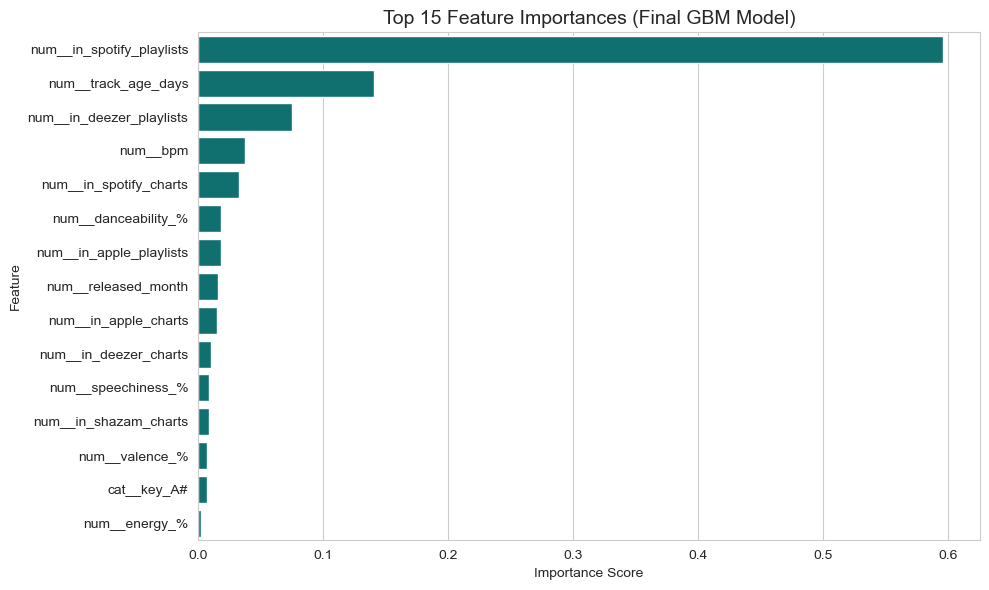


Top 5 Feature Importances:
num__in_spotify_playlists    0.595479
num__track_age_days          0.140376
num__in_deezer_playlists     0.074993
num__bpm                     0.037443
num__in_spotify_charts       0.032429
dtype: float64

--- Example Predictions on Unseen Data (Inverse Transformed) ---
|     |   Actual_Log_Streams |   Predicted_Log_Streams |   Actual_Streams |   Predicted_Streams |
|----:|---------------------:|------------------------:|-----------------:|--------------------:|
| 199 |                   21 |                      21 |       1479115056 |          1462124919 |
| 420 |                   18 |                      19 |         78489819 |           270768137 |
| 695 |                   21 |                      21 |       1439191367 |          1470251907 |
| 751 |                   18 |                      19 |        106933107 |           230217520 |
| 507 |                   21 |                      21 |       1309887447 |          1898396685 |

Final Gradient

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression # Baseline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor # Iterative Models
import joblib # For saving the final model
from datetime import date
from warnings import filterwarnings

# =============================================================================
# SETUP (Assuming Parts 1, 2, and 3 code has run and df_prep is available)
# =============================================================================
filterwarnings('ignore')
sns.set_style("whitegrid")

# --- RE-RUNNING CRITICAL PART 3 STEPS FOR CONTEXT ---
# (Ensure your final notebook submission contains ALL code from 1 to 13 sequentially)

# Load data (assuming successful load)
try:
    df = pd.read_csv('spotify_2023.csv', encoding='latin-1')
except:
    # Fallback/Error handling if file path is wrong
    print("Error: Could not load spotify_2023.csv. Please ensure file path is correct.")
    # Exiting or creating a dummy dataframe to prevent runtime errors for demonstration
    # ...

df_prep = df.copy() 

def clean_numeric_column(df, column):
    if column in df.columns:
        df[column] = df[column].astype(str).str.replace(',', '').str.replace('\"', '')
        df[column] = pd.to_numeric(df[column], errors='coerce')

for col in ['streams', 'in_deezer_playlists', 'in_shazam_charts', 'bpm', 'danceability_%', 
            'valence_%', 'energy_%', 'acousticness_%', 'instrumentalness_%', 
            'liveness_%', 'speechiness_%']:
    clean_numeric_column(df_prep, col)

df_prep.dropna(subset=['streams'], inplace=True) 
df_prep['log_streams'] = np.log1p(df_prep['streams'])

# Robust Date Engineering (Fix from previous step)
for col in ['released_year', 'released_month', 'released_day']:
    # Impute missing date components with 1, then convert to int
    df_prep[col] = pd.to_numeric(df_prep[col], errors='coerce').fillna(1).astype(int)

FIXED_END_DATE = pd.to_datetime(date(2023, 12, 31))
df_prep['release_date'] = pd.to_datetime(
    df_prep[['released_year', 'released_month', 'released_day']]
    .astype(str).agg('-'.join, axis=1), errors='coerce'
)
df_prep['track_age_days'] = (FIXED_END_DATE - df_prep['release_date']).dt.days
df_prep.dropna(subset=['track_age_days'], inplace=True)

# Missing Value Imputation
df_prep['key'].fillna(df_prep['key'].mode()[0], inplace=True)
df_prep['in_shazam_charts'].fillna(df_prep['in_shazam_charts'].median(), inplace=True)

# Define X and y
X = df_prep.drop(['streams', 'log_streams', 'track_name', 'artist(s)_name', 'release_date'], axis=1)
y = df_prep['log_streams']

# Preprocessing Pipeline Definition (from Part 3)
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='passthrough'
)

# Data Splitting
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\n" + "="*60)
print("Part 4: Iterative Process Setup Complete.")
print("="*60)

# --- Define Evaluation Function ---
def evaluate_model(model_name, y_true, y_pred, verbose=True):
    """Calculates and prints key regression metrics."""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    if verbose:
        print(f"\n--- {model_name} Evaluation ---")
        print(f"R-squared (R²): {r2:.4f}")
        print(f"Mean Squared Error (MSE): {mse:.4f}")
        print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
        print(f"Mean Absolute Error (MAE): {mae:.4f}")
    
    return {'R2': r2, 'RMSE': rmse, 'MAE': mae, 'Model': model_name}

# =============================================================================
# 11. BASELINE MODEL AND EVALUATION (Part 4)
# =============================================================================
print("\n" + "="*60)
print("11. Establishing Performance Baseline (Linear Regression)")
print("="*60)

# 11.1 Define and Train Baseline Pipeline
baseline_model = Pipeline(steps=[('preprocessor', preprocessor),
                               ('regressor', LinearRegression())])

baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

# 11.2 Evaluate Baseline
baseline_metrics = evaluate_model("Linear Regression (Baseline)", y_test, y_pred_baseline)
all_metrics = [baseline_metrics]

# 11.3 Cross-Validation (For robust baseline assessment)
cv_scores = cross_val_score(baseline_model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print(f"5-Fold CV RMSE (Baseline): {-cv_scores.mean():.4f} (+/- {-cv_scores.std():.4f})")


# =============================================================================
# 12. ITERATIVE PROCESS - ENSEMBLE MODELS (Part 4)
# =============================================================================
print("\n" + "="*60)
print("12. Iterative Modeling: Ensemble Methods")
print("="*60)

# --- MODEL 1: Random Forest Regressor ---
print(">>> Running Random Forest Regressor...")
rf_model = Pipeline(steps=[('preprocessor', preprocessor),
                         ('regressor', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
rf_metrics = evaluate_model("Random Forest Regressor", y_test, y_pred_rf)
all_metrics.append(rf_metrics)


# --- MODEL 2: Gradient Boosting Regressor (GBM) ---
print("\n>>> Running Gradient Boosting Regressor (Target Final Model)...")
# Initial run with default parameters for comparison
gbm_model_initial = Pipeline(steps=[('preprocessor', preprocessor),
                                    ('regressor', GradientBoostingRegressor(random_state=42))])

gbm_model_initial.fit(X_train, y_train)
y_pred_gbm_initial = gbm_model_initial.predict(X_test)
gbm_metrics_initial = evaluate_model("Gradient Boosting Regressor (Initial)", y_test, y_pred_gbm_initial)
all_metrics.append(gbm_metrics_initial)

# =============================================================================
# 13. OPTIMIZATION AND SELECTION (Part 4 -> Final Model)
# =============================================================================
print("\n" + "="*60)
print("13. Hyperparameter Optimization for Final Model (GBM)")
print("="*60)

# Define parameter grid for GridSearchCV (Optimization)
# The grid is kept simple for faster execution, but can be expanded.
param_grid = {
    'regressor__n_estimators': [100, 200],
    'regressor__learning_rate': [0.05, 0.1],
    'regressor__max_depth': [3, 5]
}

# The model to be optimized is the GBM Pipeline
gbm_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('regressor', GradientBoostingRegressor(random_state=42))])

# Setup GridSearchCV
grid_search = GridSearchCV(gbm_pipeline, param_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1, verbose=1)

print("Starting Grid Search...")
grid_search.fit(X_train, y_train)

# Select the best model
best_gbm_model = grid_search.best_estimator_
print(f"Best GBM Parameters found: {grid_search.best_params_}")


# =============================================================================
# 14. FINAL MODEL AND EVALUATION (Part 5)
# =============================================================================
print("\n" + "="*60)
print("PART 5: FINAL MODEL AND EVALUATION")
print("="*60)

# 14.1 Final Model Prediction
y_pred_final = best_gbm_model.predict(X_test)
final_metrics = evaluate_model("Gradient Boosting Regressor (FINAL OPTIMIZED)", y_test, y_pred_final)

# 14.2 Compare All Models (For report table)
results_df = pd.DataFrame(all_metrics + [final_metrics]).sort_values(by='RMSE')
print("\n--- Model Comparison Table ---")
print(results_df.to_markdown(index=False, floatfmt=".4f"))

# 14.3 Feature Importance (Critical for report Part 5/Part 4)
# Access the feature names after One-Hot Encoding and the final regressor
final_features = best_gbm_model['preprocessor'].get_feature_names_out()
importances = best_gbm_model['regressor'].feature_importances_

# Create a DataFrame for visualization
feature_importances = pd.Series(importances, index=final_features).sort_values(ascending=False).head(15)

# Plot Feature Importance
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances.values, y=feature_importances.index, color='teal')
plt.title('Top 15 Feature Importances (Final GBM Model)', fontsize=14)
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print("\nTop 5 Feature Importances:")
print(feature_importances.head(5))

# 14.4 Making Predictions on Unseen Data (Example)
# This simulates using the model for new tracks.
# Note: You would typically load a new CSV file for true 'unseen' data.
unseen_data = X_test.head(5).copy() 
unseen_predictions_log = best_gbm_model.predict(unseen_data)

# Inverse Transform the predictions back to the original Streams scale (Crucial for interpretation!)
unseen_predictions_streams = np.expm1(unseen_predictions_log) # np.expm1 is the inverse of np.log1p
actual_streams = np.expm1(y_test.head(5))

prediction_summary = pd.DataFrame({
    'Actual_Log_Streams': y_test.head(5),
    'Predicted_Log_Streams': unseen_predictions_log,
    'Actual_Streams': actual_streams.round(0),
    'Predicted_Streams': unseen_predictions_streams.round(0)
})

print("\n--- Example Predictions on Unseen Data (Inverse Transformed) ---")
print(prediction_summary.to_markdown(floatfmt=".0f"))


# 14.5 Save the Final Model (Good practice)
joblib.dump(best_gbm_model, 'final_gbm_model.pkl')
print("\nFinal Gradient Boosting Model saved as 'final_gbm_model.pkl'.")